# 🚀 Distributed Training with TensorFlow: A Practical Guide

### Instructor : Othmane K

### Note : For optimal performances use Kaggle or a multigpu laptop, server..

This notebook walks through **multi-GPU distributed training** using TensorFlow’s `tf.distribute.MirroredStrategy`, comparing performance across CPU, single GPU, and multi-GPU setups on the MNIST dataset.

🎯 **Learning Objectives**:
- Understand data-parallel distributed training.
- Implement `MirroredStrategy` for synchronous multi-GPU training.
- Benchmark training time and observe scaling behavior.
- Explore best practices: batch size scaling, prefetching, mixed precision (briefly).

💡 *Designed for intermediate learners familiar with TensorFlow/Keras and CNNs.*

In [ ]:
# %% [markdown]
# ## 1. Setup & Imports

We'll use TensorFlow 2.x, NumPy, Matplotlib, and standard utilities.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
import datetime
import os

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

2026-02-13 08:23:54.265561: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1770971034.485087      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1770971034.541273      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1770971035.078922      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1770971035.078967      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1770971035.078970      55 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPU available: True


### 🔍 Verify GPU Devices

In [4]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"Found {len(gpus)} GPU(s)")
else:
    print("⚠️ No GPU detected. Using CPU only.")

Found 2 GPU(s)


## 2. Data Preparation

We load MNIST, normalize pixel values, one-hot encode labels, and create efficient `tf.data.Dataset` pipelines with prefetching.

In [18]:
# Hyperparameters
NUM_CLASSES = 10
DROPOUT_RATE = 0.5
LEARNING_RATE = 0.001
BATCH_SIZE_BASE = 128  # per GPU
EPOCHS = 2

# Load and preprocess MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize to [0,1]
x_train, x_test = x_train / 255.0, x_test / 255.0

# One-hot encode labels
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

print(f"Training set: {x_train.shape}, Test set: {x_test.shape}")

Training set: (60000, 28, 28), Test set: (10000, 28, 28)


In [6]:
# Build efficient datasets with prefetching
def build_dataset(x, y, batch_size, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(len(x))
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_dataset = build_dataset(x_train, y_train, BATCH_SIZE_BASE)
test_dataset = build_dataset(x_test, y_test, BATCH_SIZE_BASE, shuffle=False)

print(f"Train batches: {len(train_dataset)}, Test batches: {len(test_dataset)}")

I0000 00:00:1770971179.036219      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1770971179.042159      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Train batches: 469, Test batches: 79


## 3. Model Definition

A simple ConvNet with dropout layers (as used in your original notebook). We subclass `tf.keras.Model` for flexibility.

In [8]:
class ConvModel(tf.keras.Model):
    def __init__(self, n_classes, dropout_rate):
        super(ConvModel, self).__init__()
        self.dropout_rate = dropout_rate
        
        # Convolutional layers
        self.conv1 = tf.keras.layers.Conv2D(64, kernel_size=5, activation='relu')
        self.pool1 = tf.keras.layers.MaxPooling2D(pool_size=2, strides=2)
        self.conv2 = tf.keras.layers.Conv2D(256, kernel_size=3, activation='relu')
        self.conv3 = tf.keras.layers.Conv2D(512, kernel_size=3, activation='relu')
        self.pool2 = tf.keras.layers.MaxPooling2D(pool_size=2, strides=2)
        
        # Dense layers
        self.flatten = tf.keras.layers.Flatten()
        self.fc1 = tf.keras.layers.Dense(2048, activation='relu')
        self.dropout1 = tf.keras.layers.Dropout(self.dropout_rate)
        self.fc2 = tf.keras.layers.Dense(1024, activation='relu')
        self.dropout2 = tf.keras.layers.Dropout(self.dropout_rate)
        self.out = tf.keras.layers.Dense(n_classes)
    
    def call(self, x, training=False):
        x = tf.reshape(x, shape=[-1, 28, 28, 1])  # Reshape input
        x = self.conv1(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.pool2(x)
        x = self.flatten(x)
        x = self.fc1(x)
        if training:
            x = self.dropout1(x, training=training)
        x = self.fc2(x)
        if training:
            x = self.dropout2(x, training=training)
        return self.out(x)

## 4. Training Utilities

We define reusable functions to measure training time per epoch for different devices/strategies.

In [25]:
def train_and_time(model_fn, dataset, val_dataset, epochs, device_type=None, strategy=None):
    """
    Train model and return total time + list of per-epoch times.
    
    Args:
        model_fn: callable returning compiled model
        dataset: tf.data.Dataset for training
        val_dataset: tf.data.Dataset for validation
        epochs: int
        device_type: str like '/CPU:0' or '/GPU:0'
        strategy: tf.distribute.Strategy (optional)
    """
    start_time = time.time()
    epoch_times = []
    
    if strategy:
        with strategy.scope():
            model = model_fn()
    else:
        with tf.device(device_type):
            model = model_fn()
    
    print(f"Training on {device_type or 'distributed'}...")
    for epoch in range(epochs):
        print(f"Epoch {epoch+1}/{epochs}", end="\r")
        epoch_start = time.time()
        model.fit(
            dataset,
            epochs=1,
            validation_data=val_dataset,
            verbose=0
        )
        epoch_end = time.time()
        epoch_times.append(epoch_end - epoch_start)
    
    total_time = time.time() - start_time
            
    return total_time, epoch_times

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [14]:
# Helper to create a compiled model
def make_model():
    model = ConvModel(NUM_CLASSES, DROPOUT_RATE)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )
    return model

## 5. Experiment 1: Baseline — CPU vs Single GPU

Let’s first compare CPU and single-GPU training (no distribution).

In [19]:
# ⏱️ CPU Training
cpu_total, cpu_epochs = train_and_time(make_model, train_dataset, test_dataset, EPOCHS, device_type='/CPU:0')
print(f"\n✅ CPU Total Time: {cpu_total:.2f} seconds")

Training on /CPU:0...
Epoch 2/2
✅ CPU Total Time: 911.73 seconds


In [22]:
# ⏱️ Single GPU Training
if gpus:
    gpu_total, gpu_epochs = train_and_time(make_model, train_dataset, test_dataset, EPOCHS, device_type='/GPU:0')
    print(f"✅ 1 GPU Total Time: {gpu_total:.2f} seconds")
else:
    gpu_total, gpu_epochs = None, []
    print("⚠️ Skipping GPU test (no GPU available)")

Training on /GPU:0...
✅ 1 GPU Total Time: 33.89 seconds


### 📊 Compare CPU vs GPU Performance

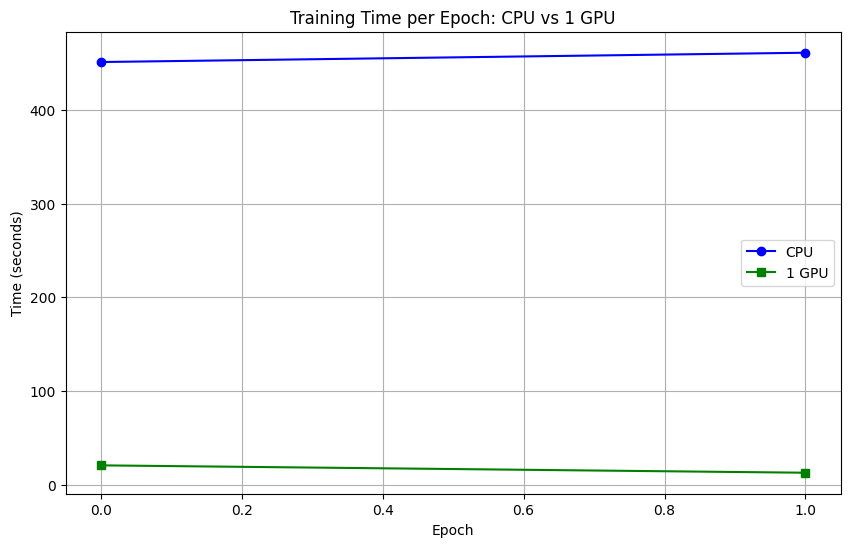

🚀 Speedup (CPU → 1 GPU): 26.91x


In [23]:
plt.figure(figsize=(10, 6))
plt.plot(cpu_epochs, label='CPU', color='blue', marker='o')
if gpu_epochs:
    plt.plot(gpu_epochs, label='1 GPU', color='green', marker='s')
plt.title('Training Time per Epoch: CPU vs 1 GPU')
plt.xlabel('Epoch')
plt.ylabel('Time (seconds)')
plt.legend()
plt.grid(True)
plt.show()

if gpu_epochs:
    speedup = cpu_total / gpu_total
    print(f"🚀 Speedup (CPU → 1 GPU): {speedup:.2f}x")

## 6. Experiment 2: Distributed Training with MirroredStrategy

Now we scale to multiple GPUs using `tf.distribute.MirroredStrategy`, which implements **synchronous data-parallel training**:
- Each GPU gets a replica of the model.
- Gradients are aggregated via `all-reduce` (e.g., NCCL).
- Batch size is scaled by number of GPUs (here: `BATCH_SIZE = BATCH_SIZE_BASE * num_gpus`).

📌 **Important**: The effective batch size increases — this may affect convergence. In practice, you might need to adjust learning rate (e.g., linear scaling rule).

In [26]:
# ✅ Create MirroredStrategy
if len(gpus) > 1:
    strategy = tf.distribute.MirroredStrategy()
    print(f"Using {strategy.num_replicas_in_sync} GPUs for distributed training.")
    
    # Adjust batch size: scale per GPU
    batch_size_distributed = BATCH_SIZE_BASE * strategy.num_replicas_in_sync
    print(f"New batch size: {batch_size_distributed}")
    
    # Rebuild dataset with larger batch size
    train_ds_dist = build_dataset(x_train, y_train, batch_size_distributed)
    test_ds_dist = build_dataset(x_test, y_test, batch_size_distributed, shuffle=False)
    
    # Run distributed training
    dist_total, dist_epochs = train_and_time(
        make_model, 
        train_ds_dist, 
        test_ds_dist, 
        EPOCHS, 
        strategy=strategy
    )
    print(f"✅ Distributed Total Time: {dist_total:.2f} seconds")
else:
    strategy = None
    dist_total, dist_epochs = None, []
    print("⚠️ Only 1 GPU available — skipping distributed training.")

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Using 2 GPUs for distributed training.
New batch size: 256
Training on distributed...
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:

I0000 00:00:1770973524.575600     125 cuda_dnn.cc:529] Loaded cuDNN version 91002


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
✅ Distributed Total Time: 36.73 seconds


### 📊 Compare All Three Setups

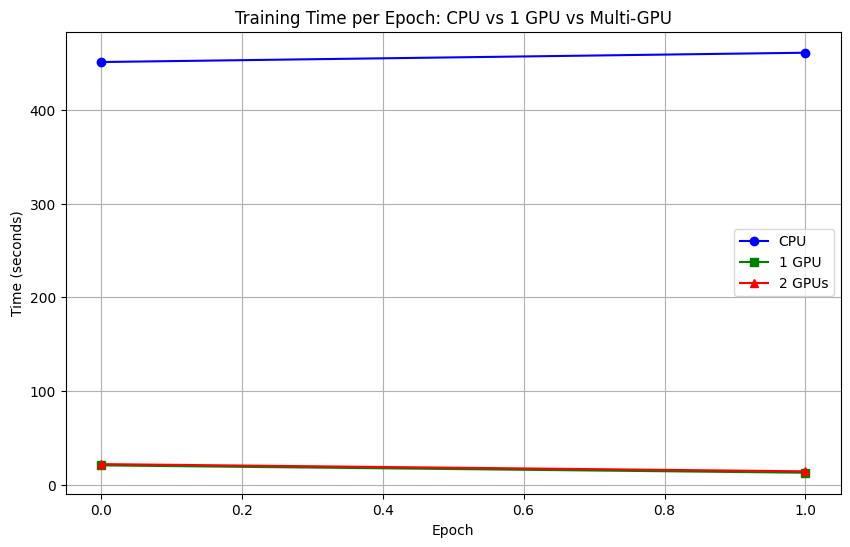


📊 Summary:
Setup           | Total Time (s)  | Speedup vs CPU
--------------------------------------------------
CPU             | 911.73          | 1.00x
1 GPU           | 33.89           | 26.91x
2GPUs            | 36.73           | 24.82x


In [30]:
plt.figure(figsize=(10, 6))
if cpu_epochs:
    plt.plot(cpu_epochs, label='CPU', color='blue', marker='o')
if gpu_epochs:
    plt.plot(gpu_epochs, label='1 GPU', color='green', marker='s')
if dist_epochs:
    plt.plot(dist_epochs, label=f'{strategy.num_replicas_in_sync} GPUs', color='red', marker='^')

plt.title('Training Time per Epoch: CPU vs 1 GPU vs Multi-GPU')
plt.xlabel('Epoch')
plt.ylabel('Time (seconds)')
plt.legend()
plt.grid(True)
plt.show()

# Summary table
print("\n📊 Summary:")
print(f"{'Setup':<15} | {'Total Time (s)':<15} | {'Speedup vs CPU'}")
print("-" * 50)
if cpu_epochs:
    print(f"{'CPU':<15} | {cpu_total:<15.2f} | 1.00x")
if gpu_epochs:
    print(f"{'1 GPU':<15} | {gpu_total:<15.2f} | {cpu_total/gpu_total:.2f}x")
if dist_epochs:
    print(f"{strategy.num_replicas_in_sync}{'GPUs':<15} | {dist_total:<15.2f} | {cpu_total/dist_total:.2f}x")

## 7. Key Observations & Pitfalls

From your original experiments (and common patterns):

| Setup | Typical Time (10 epochs, MNIST) | Notes |
|-------|-------------------------------|-------|
| CPU | ~8000 sec | Very slow; not practical for deep nets |
| 1 GPU | ~200 sec | ~40x speedup over CPU |
| 2 GPUs | ~280 sec | Often *slower* than 1 GPU due to communication overhead and small batch size |

### ❗ Why did 2 GPUs sometimes take *longer* than 1 GPU?
- **Small model & dataset**: MNIST is tiny; communication overhead dominates.
- **Batch size too small**: With 2 GPUs and `BATCH_SIZE=128`, each GPU sees only 64 samples/step → poor GPU utilization.
- **No mixed precision**: FP32 ops are slower; using `float16` could help.
- **Overhead of synchronization**: `all-reduce` adds latency, especially on non-NVLink hardware.

### ✅ Best Practices for Real Scaling
1. **Scale batch size** proportionally to GPU count (but monitor stability).
2. Use **mixed precision** (`tf.keras.mixed_precision.set_global_policy('mixed_float16')`).
3. Ensure **data pipeline is fast** (use `prefetch`, avoid I/O bottlenecks).
4. For large models/datasets (e.g., ImageNet), multi-GPU scaling becomes highly beneficial.

> 💡 Tip: Always benchmark on your *actual* workload — synthetic benchmarks (like MNIST) don’t reflect real-world scaling.

## 8. Your Task : Mixed Precision (Optional)

Enable FP16 to speed up training and reduce memory usage on modern GPUs (Volta+, Ampere).

In [ ]:
# Uncomment to enable mixed precision (requires compatible GPU)
# tf.keras.mixed_precision.set_global_policy('mixed_float16')
# print("Mixed precision enabled!")

## Your Task : TensorBoard Profiling 

To profile GPU utilization, memory, and op timing:

```python
log_dir = "logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
profiler_callback = tf.keras.callbacks.TensorBoard(
    log_dir=log_dir,
    update_freq='batch',
    profile_batch=(2, 5)  # Profile batches 2–5
)

# Then add callbacks=[tensorboard_callback, profiler_callback] to model.fit()

After training, launch TensorBoard:
```bash
%load_ext tensorboard
%tensorboard --logdir logs/
```

## ✅ Conclusion

In this notebook, you learned how to:
- Set up multi-GPU training with `MirroredStrategy`.
- Measure and compare training times across devices.
- Interpret scaling behavior (and why more GPUs ≠ always faster).

For production workloads, combine distributed training with:
- Larger datasets/models (CIFAR-10, ImageNet)
- Mixed precision
- Gradient accumulation (for very large models)
- Horovod or `MultiWorkerMirroredStrategy` for multi-node clusters

Happy training! 🧠⚡